# No Regularization (OLS) vs. Ridge ($L_2$) vs. Lasso ($L_1$) Regression

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Set random seed for reproducibility
np.random.seed(42)

# Configure Matplotlib styling
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['font.size'] = 11

## Synthetic Data Generation: High-Degree Polynomial

We generate synthetic data from a true low-order polynomial underlying signal:
$$y_{\text{true}} = W_0 + W_1 x + W_2 x^2 + W_3 x^3$$
where:
- $W_0 = 2.0$
- $W_1 = -1.5$
- $W_2 = -0.8$
- $W_3 = 0.3$

We will add Gaussian noise $\epsilon \sim \mathcal{N}(0, \sigma^2)$ and subsequently fit a **degree-10 polynomial** (11 features). This sets up a scenario where features $x^4, x^5, \dots, x^{10}$ are irrelevant and will cause unregularized models to overfit severely.

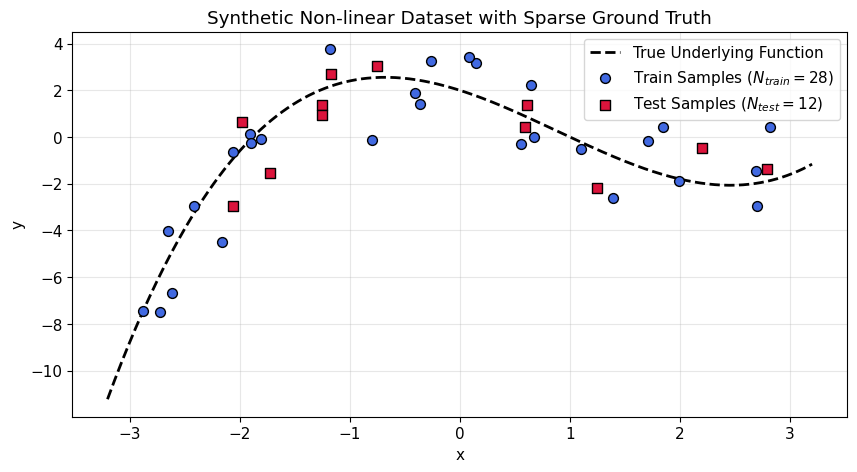

In [2]:
# Ground truth parameters
W0_true = 2.0
W1_true = -1.5
W2_true = -0.8
W3_true = 0.3

num_samples = 40
noise_std = 1.5

# Generate non-uniform x samples in [-3, 3]
X_raw = np.sort(np.random.uniform(-3.0, 3.0, num_samples))

# Ground truth function
Y_true = W0_true + W1_true * X_raw + W2_true * (X_raw**2) + W3_true * (X_raw**3)

# Additive Gaussian noise
Y_noisy = Y_true + np.random.normal(0, noise_std, size=num_samples)

# Split into training (70%) and testing (30%)
indices = np.random.permutation(num_samples)
train_size = int(num_samples * 0.7)

train_idx = indices[:train_size]
test_idx = indices[train_size:]

X_train_raw, Y_train = X_raw[train_idx], Y_noisy[train_idx]
X_test_raw, Y_test = X_raw[test_idx], Y_noisy[test_idx]

# Dense grid for smooth curve visualization
X_grid = np.linspace(-3.2, 3.2, 400)
Y_grid_true = W0_true + W1_true * X_grid + W2_true * (X_grid**2) + W3_true * (X_grid**3)

# Visualize generated dataset
plt.figure(figsize=(10, 5))
plt.plot(X_grid, Y_grid_true, 'k--', linewidth=2, label='True Underlying Function')
plt.scatter(X_train_raw, Y_train, color='royalblue', s=50, edgecolors='k', zorder=5, label='Train Samples ($N_{train}=28$)')
plt.scatter(X_test_raw, Y_test, color='crimson', s=50, marker='s', edgecolors='k', zorder=5, label='Test Samples ($N_{test}=12$)')
plt.title('Synthetic Non-linear Dataset with Sparse Ground Truth')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

## 3. Polynomial Feature Expansion and Standardization

To enable polynomial regression of degree $P$, we map each scalar $x_i$ to a feature vector:
$$\phi(x_i) = \begin{bmatrix} 1 & x_i & x_i^2 & x_i^3 & \dots & x_i^P \end{bmatrix}^T$$

### Importance of Feature Scaling in Regularization:
Because $x^p$ scales rapidly with power $p$ (e.g., $3^{10} = 59049$), higher-order features would be unfairly over-penalized if not standardized. 
We standardize all non-bias features ($j \ge 1$) to have **zero mean** and **unit variance** based on the training set statistics:

$$\tilde{x}_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j}, \quad j = 1, \dots, P$$

In [3]:
DEGREE = 10

def create_polynomial_features(x, degree=DEGREE):
    """
    Transforms 1D array of x values into a Vandermonde-like feature matrix.
    Shape: (N, degree + 1)
    """
    X_poly = np.column_stack([x**d for d in range(degree + 1)])
    return X_poly

# Create polynomial feature matrices
X_train_poly = create_polynomial_features(X_train_raw, degree=DEGREE)
X_test_poly = create_polynomial_features(X_test_raw, degree=DEGREE)
X_grid_poly = create_polynomial_features(X_grid, degree=DEGREE)

# Standardize non-intercept columns (columns 1 to DEGREE)
mean_feat = np.mean(X_train_poly[:, 1:], axis=0)
std_feat = np.std(X_train_poly[:, 1:], axis=0)
# Prevent division by zero
std_feat[std_feat == 0.0] = 1.0

def standardize_features(X_poly, mean_vec, std_vec):
    X_scaled = X_poly.copy()
    X_scaled[:, 1:] = (X_poly[:, 1:] - mean_vec) / std_vec
    return X_scaled

X_train_scaled = standardize_features(X_train_poly, mean_feat, std_feat)
X_test_scaled = standardize_features(X_test_poly, mean_feat, std_feat)
X_grid_scaled = standardize_features(X_grid_poly, mean_feat, std_feat)

print(f"Feature matrix shape (Train): {X_train_scaled.shape}")
print(f"Feature matrix shape (Test):  {X_test_scaled.shape}")

Feature matrix shape (Train): (28, 11)
Feature matrix shape (Test):  (12, 11)


In [4]:
def compute_mse_loss(X, y, w):
    """Computes Mean Squared Error (MSE) loss."""
    N = X.shape[0]
    predictions = X @ w
    return (1.0 / (2.0 * N)) * np.sum((predictions - y)**2)

def soft_threshold(v, threshold):
    """Vectorized soft-thresholding operator for L1 proximal step."""
    return np.sign(v) * np.maximum(np.abs(v) - threshold, 0.0)

def fit_ols(X, y, epochs=15000, lr=0.01):
    """Ordinary Least Squares via Batch Gradient Descent."""
    N, D = X.shape
    w = np.zeros(D)
    loss_history = []
    
    for _ in range(epochs):
        grad = (1.0 / N) * (X.T @ (X @ w - y))
        w -= lr * grad
        loss_history.append(compute_mse_loss(X, y, w))
        
    return w, loss_history

def fit_ridge(X, y, alpha=1.0, epochs=15000, lr=0.01):
    """Ridge Regression (L2) via Gradient Descent with Weight Decay."""
    N, D = X.shape
    w = np.zeros(D)
    loss_history = []
    
    for _ in range(epochs):
        grad = (1.0 / N) * (X.T @ (X @ w - y))
        # Regularize all weights except bias (w[0])
        grad[1:] += alpha * w[1:]
        w -= lr * grad
        
        reg_loss = compute_mse_loss(X, y, w) + (alpha / 2.0) * np.sum(w[1:]**2)
        loss_history.append(reg_loss)
        
    return w, loss_history

def fit_lasso(X, y, alpha=0.1, epochs=15000, lr=0.01):
    """Lasso Regression (L1) via Proximal Gradient Descent (ISTA)."""
    N, D = X.shape
    w = np.zeros(D)
    loss_history = []
    
    for _ in range(epochs):
        # 1. Gradient step on MSE
        grad = (1.0 / N) * (X.T @ (X @ w - y))
        w_temp = w - lr * grad
        
        # 2. Proximal (Soft-Thresholding) step on non-bias coefficients
        w[0] = w_temp[0]  # Bias is unpenalized
        w[1:] = soft_threshold(w_temp[1:], lr * alpha)
        
        reg_loss = compute_mse_loss(X, y, w) + alpha * np.sum(np.abs(w[1:]))
        loss_history.append(reg_loss)
        
    return w, loss_history

## Model Training and Convergence

In [5]:
# Set hyperparameters
EPOCHS = 20000
LEARNING_RATE = 0.05
LAMBDA_RIDGE = 0.5
LAMBDA_LASSO = 0.15

# Fit models
w_ols, loss_ols = fit_ols(X_train_scaled, Y_train, epochs=EPOCHS, lr=LEARNING_RATE)
w_ridge, loss_ridge = fit_ridge(X_train_scaled, Y_train, alpha=LAMBDA_RIDGE, epochs=EPOCHS, lr=LEARNING_RATE)
w_lasso, loss_lasso = fit_lasso(X_train_scaled, Y_train, alpha=LAMBDA_LASSO, epochs=EPOCHS, lr=LEARNING_RATE)

print("Training completed successfully!")

Training completed successfully!


## Visual Comparison of Model Prediction Curves vs. Ground Truth

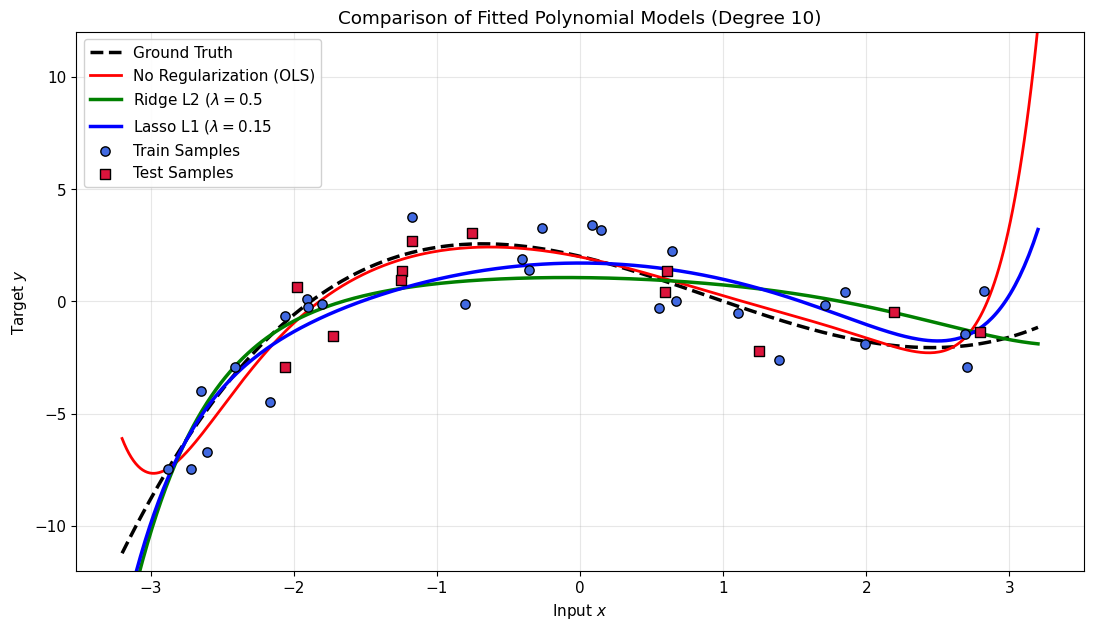

In [18]:
# Generate continuous predictions on grid
y_grid_ols = X_grid_scaled @ w_ols
y_grid_ridge = X_grid_scaled @ w_ridge
y_grid_lasso = X_grid_scaled @ w_lasso

plt.figure(figsize=(13, 7))
plt.plot(X_grid, Y_grid_true, 'k--', linewidth=2.5, label='Ground Truth')
plt.plot(X_grid, y_grid_ols, 'r-', linewidth=2, label='No Regularization (OLS)')
plt.plot(X_grid, y_grid_ridge, 'g-', linewidth=2.5, label=f'Ridge L2 ($\lambda={LAMBDA_RIDGE}$')
plt.plot(X_grid, y_grid_lasso, 'b-', linewidth=2.5, label=f'Lasso L1 ($\lambda={LAMBDA_LASSO}$')

plt.scatter(X_train_raw, Y_train, color='royalblue', s=45, edgecolors='k', zorder=5, label='Train Samples')
plt.scatter(X_test_raw, Y_test, color='crimson', s=45, marker='s', edgecolors='k', zorder=5, label='Test Samples')

plt.ylim(-12, 12)
plt.title('Comparison of Fitted Polynomial Models (Degree 10)')
plt.xlabel('Input $x$')
plt.ylabel('Target $y$')
plt.legend(loc='best', framealpha=0.9)
plt.show()

## Learned Coefficients & Sparsity

Here we compare the learned standardized weights for each polynomial power $x^0, x^1, \dots, x^{10}$.
- Notice how **OLS** assigns large non-zero weights to higher-order spurious terms ($x^4, \dots, x^{10}$).
- Notice how **Ridge** dampens all weights smoothly but leaves them non-zero.
- Notice how **Lasso** zeroes out the higher-degree weights completely, discovering the underlying sparse structure.

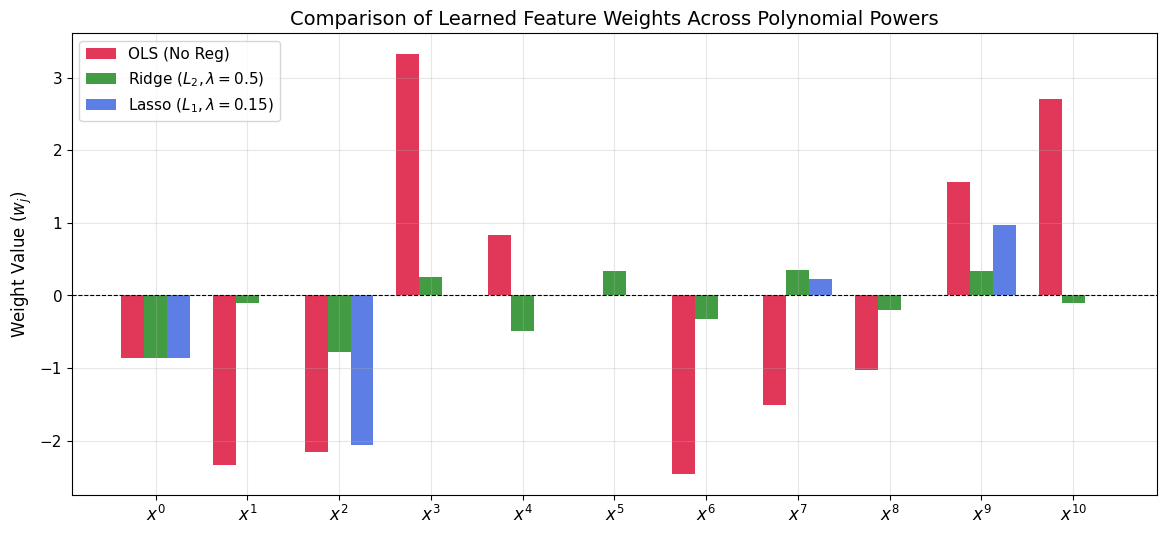

Feature    | OLS Weight      | Ridge Weight    | Lasso Weight   
$x^{0}$    | -0.8568         | -0.8568         | -0.8568        
$x^{1}$    | -2.3361         | -0.1023         | -0.0000        
$x^{2}$    | -2.1572         | -0.7791         | -2.0543        
$x^{3}$    | 3.3233          | 0.2560          | 0.0000         
$x^{4}$    | 0.8303          | -0.4929         | -0.0000        
$x^{5}$    | 0.0050          | 0.3436          | 0.0000         
$x^{6}$    | -2.4615         | -0.3201         | -0.0000        
$x^{7}$    | -1.5063         | 0.3523          | 0.2266         
$x^{8}$    | -1.0248         | -0.1972         | -0.0000        
$x^{9}$    | 1.5694          | 0.3407          | 0.9733         
$x^{10}$   | 2.7017          | -0.1014         | -0.0000        


In [7]:
features = [f'$x^{{{i}}}$' for i in range(DEGREE + 1)]
x_indices = np.arange(len(features))
bar_width = 0.25

fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(x_indices - bar_width, w_ols, width=bar_width, label='OLS (No Reg)', color='crimson', alpha=0.85)
ax.bar(x_indices, w_ridge, width=bar_width, label=f'Ridge ($L_2, \lambda={LAMBDA_RIDGE}$)', color='forestgreen', alpha=0.85)
ax.bar(x_indices + bar_width, w_lasso, width=bar_width, label=f'Lasso ($L_1, \lambda={LAMBDA_LASSO}$)', color='royalblue', alpha=0.85)

ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_xticks(x_indices)
ax.set_xticklabels(features, fontsize=12)
ax.set_ylabel('Weight Value ($w_j$)', fontsize=12)
ax.set_title('Comparison of Learned Feature Weights Across Polynomial Powers', fontsize=14)
ax.legend(fontsize=11)
plt.show()

# Print exact weight vectors
print("="*65)
print(f"{'Feature':<10} | {'OLS Weight':<15} | {'Ridge Weight':<15} | {'Lasso Weight':<15}")
print("="*65)
for i, feat in enumerate(features):
    print(f"{feat:<10} | {w_ols[i]:<15.4f} | {w_ridge[i]:<15.4f} | {w_lasso[i]:<15.4f}")
print("="*65)

## Why does $L_1$ produce exact zeros while $L_2$ does not?

Consider constrained optimization formulation:
- **Ridge:** Minimize MSE subject to $w_1^2 + w_2^2 \le C$ (**Spherical constraint**).
- **Lasso:** Minimize MSE subject to $|w_1| + |w_2| \le C$ (**Polyhedral constraint**).

The unconstrained MSE contours expand outward until they first touch the constraint region. 
Because the $L_1$ diamond has sharp corners aligned with the coordinate axes, the expanding elliptical loss contours are statistically far more likely to contact a **corner** where one or more coordinates equal zero.

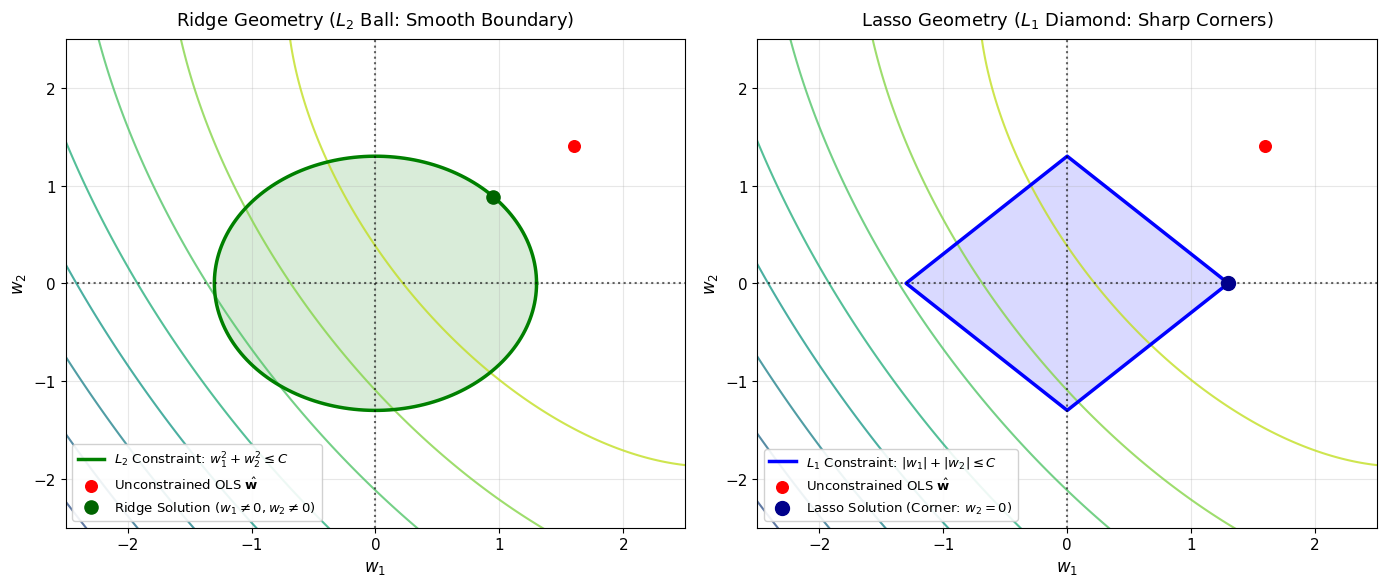

In [10]:
# Create 2D grid for parameter space (w1, w2)
w1_range = np.linspace(-3, 3, 200)
w2_range = np.linspace(-3, 3, 200)
W1_grid, W2_grid = np.meshgrid(w1_range, w2_range)

# Synthetic 2D loss surface centered at unconstrained optimum (w1_opt, w2_opt)
w1_opt, w2_opt = 1.6, 1.4
Loss_surface = (
    1.2 * (W1_grid - w1_opt) ** 2
    + 0.6 * (W2_grid - w2_opt) ** 2
    + 0.8 * (W1_grid - w1_opt) * (W2_grid - w2_opt)
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# --- Left Plot: L2 Ball (Circle) ---
radius = 1.3
circle_theta = np.linspace(0, 2 * np.pi, 200)
ax1.contour(
    W1_grid, W2_grid, Loss_surface, levels=12, cmap='viridis_r', alpha=0.8
)
ax1.plot(
    radius * np.cos(circle_theta),
    radius * np.sin(circle_theta),
    'g-',
    linewidth=2.5,
    label=r'$L_2$ Constraint: $w_1^2 + w_2^2 \leq C$',
)
ax1.fill(
    radius * np.cos(circle_theta),
    radius * np.sin(circle_theta),
    'green',
    alpha=0.15,
)
ax1.scatter(
    [w1_opt],
    [w2_opt],
    color='red',
    s=70,
    zorder=5,
    label=r'Unconstrained OLS $\hat{\mathbf{w}}$',
)
# Intersection point
ax1.scatter(
    [0.95],
    [0.88],
    color='darkgreen',
    s=90,
    zorder=6,
    label=r'Ridge Solution ($w_1 \neq 0, w_2 \neq 0$)',
)
ax1.axhline(0, color='k', linestyle=':', alpha=0.6)
ax1.axvline(0, color='k', linestyle=':', alpha=0.6)
ax1.set_xlim(-2.5, 2.5)
ax1.set_ylim(-2.5, 2.5)
ax1.set_title(
    r'Ridge Geometry ($L_2$ Ball: Smooth Boundary)', fontsize=13, pad=10
)
ax1.set_xlabel(r'$w_1$', fontsize=12)
ax1.set_ylabel(r'$w_2$', fontsize=12)
ax1.legend(loc='lower left', fontsize=9.5, framealpha=0.9)

# --- Right Plot: L1 Ball (Diamond) ---
c_l1 = 1.3
diamond_x = [c_l1, 0, -c_l1, 0, c_l1]
diamond_y = [0, c_l1, 0, -c_l1, 0]
ax2.contour(
    W1_grid, W2_grid, Loss_surface, levels=12, cmap='viridis_r', alpha=0.8
)
ax2.plot(
    diamond_x,
    diamond_y,
    'b-',
    linewidth=2.5,
    label=r'$L_1$ Constraint: $|w_1| + |w_2| \leq C$',
)
ax2.fill(diamond_x, diamond_y, 'blue', alpha=0.15)
ax2.scatter(
    [w1_opt],
    [w2_opt],
    color='red',
    s=70,
    zorder=5,
    label=r'Unconstrained OLS $\hat{\mathbf{w}}$',
)
# Corner intersection point
ax2.scatter(
    [c_l1],
    [0],
    color='darkblue',
    s=100,
    zorder=6,
    label=r'Lasso Solution (Corner: $w_2 = 0$)',
)
ax2.axhline(0, color='k', linestyle=':', alpha=0.6)
ax2.axvline(0, color='k', linestyle=':', alpha=0.6)
ax2.set_xlim(-2.5, 2.5)
ax2.set_ylim(-2.5, 2.5)
ax2.set_title(
    r'Lasso Geometry ($L_1$ Diamond: Sharp Corners)', fontsize=13, pad=10
)
ax2.set_xlabel(r'$w_1$', fontsize=12)
ax2.set_ylabel(r'$w_2$', fontsize=12)
ax2.legend(loc='lower left', fontsize=9.5, framealpha=0.9)

plt.tight_layout()
plt.show()

## Quantitative Comparison

Model              | Train MSE    | Test MSE     | ||w||_2      | Zeroed Features
OLS (No Reg)       | 1.6247       | 1.4770       | 6.4019       | 0               / 10
Ridge (L2)         | 2.4709       | 2.0684       | 1.1983       | 0               / 10
Lasso (L1)         | 2.0955       | 1.9994       | 2.2845       | 7               / 10


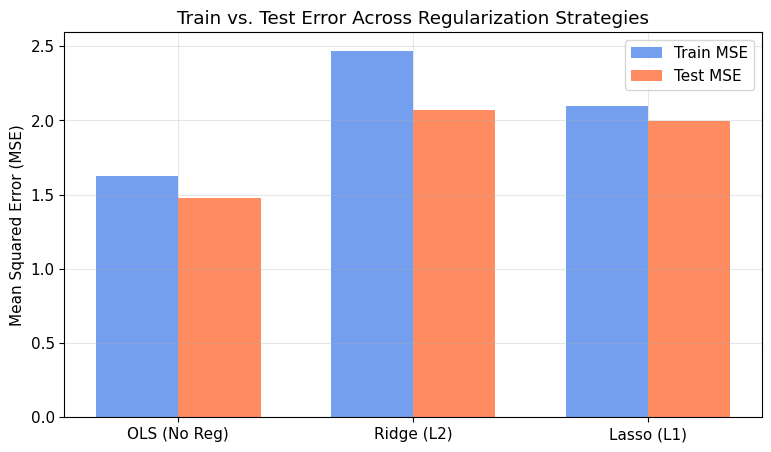

In [9]:
# Calculate evaluation metrics
def eval_model(name, w, X_tr, y_tr, X_te, y_te):
    train_mse = 2.0 * compute_mse_loss(X_tr, y_tr, w)
    test_mse = 2.0 * compute_mse_loss(X_te, y_te, w)
    l2_norm = np.linalg.norm(w[1:], 2)
    zero_weights = np.sum(np.isclose(w[1:], 0.0, atol=1e-4))
    return train_mse, test_mse, l2_norm, zero_weights

metrics = {}
metrics['OLS (No Reg)'] = eval_model('OLS', w_ols, X_train_scaled, Y_train, X_test_scaled, Y_test)
metrics['Ridge (L2)'] = eval_model('Ridge', w_ridge, X_train_scaled, Y_train, X_test_scaled, Y_test)
metrics['Lasso (L1)'] = eval_model('Lasso', w_lasso, X_train_scaled, Y_train, X_test_scaled, Y_test)

print("="*80)
print(f"{'Model':<18} | {'Train MSE':<12} | {'Test MSE':<12} | {'||w||_2':<12} | {'Zeroed Features':<15}")
print("="*80)
for name, (tr_m, te_m, l2_n, z_w) in metrics.items():
    print(f"{name:<18} | {tr_m:<12.4f} | {te_m:<12.4f} | {l2_n:<12.4f} | {z_w:<15} / {DEGREE}")
print("="*80)

# Summary bar chart
models = list(metrics.keys())
train_mses = [metrics[m][0] for m in models]
test_mses = [metrics[m][1] for m in models]

x_bar = np.arange(len(models))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(x_bar - width/2, train_mses, width, label='Train MSE', color='cornflowerblue', alpha=0.9)
plt.bar(x_bar + width/2, test_mses, width, label='Test MSE', color='coral', alpha=0.9)
plt.xticks(x_bar, models, fontsize=11)
plt.ylabel('Mean Squared Error (MSE)')
plt.title('Train vs. Test Error Across Regularization Strategies')
plt.legend()
plt.show()